# Smartventory — Notebook 01: Weekly Demand Baseline
This notebook establishes a 4-week trailing moving average baseline for product-level weekly demand forecasting across stores.
> For full theoretical background, data dictionary, and in-depth analysis, refer to `Smartventory_01_Understanding_and_Analysis.md`.

### 1. Imports
Import required standard libraries for data handling, baseline evaluation, and plotting.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['figure.dpi'] = 110

### 2. Configuration & Data Ingestion
Configure the source dataset path, verify its existence, and load the raw daily sales data.

In [2]:
DATA_PATH = 'sales_data.csv'

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Source file '{DATA_PATH}' does not exist.")

df = pd.read_csv(DATA_PATH)
print(f"Loaded '{DATA_PATH}' successfully: {df.shape[0]:,} rows, {df.shape[1]} columns.")
display(df.head())

Loaded 'sales_data.csv' successfully: 76,000 rows, 16 columns.


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


### 3. Data Validation & Profiling
Validate column presence, convert dates to datetime, verify chronological ordering, and check for missing values or duplicates.

In [3]:
# Check required columns
expected_columns = [
    'Date', 'Store ID', 'Product ID', 'Category', 'Region', 
    'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 
    'Discount', 'Weather Condition', 'Promotion', 'Competitor Pricing', 
    'Seasonality', 'Epidemic', 'Demand'
]
assert all(col in df.columns for col in expected_columns), "Missing required columns!"

# Convert Date to datetime and sort chronologically
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
assert df['Date'].isna().sum() == 0, "Invalid dates found!"
df = df.sort_values(by=['Date', 'Store ID', 'Product ID']).reset_index(drop=True)

# Integrity checks
print(f"Total Rows:                          {len(df):,}")
print(f"Date Range:                          {df['Date'].min().strftime('%Y-%m-%d')} to {df['Date'].max().strftime('%Y-%m-%d')} ({df['Date'].nunique()} unique dates)")
print(f"Unique Stores / Products:            {df['Store ID'].nunique()} stores, {df['Product ID'].nunique()} products")
print(f"Missing Values:                      {df.isnull().sum().sum()}")
print(f"Duplicate Rows:                      {df.duplicated().sum()}")
print(f"Duplicate (Product, Store, Date):    {df.duplicated(subset=['Product ID', 'Store ID', 'Date']).sum()}")
print(f"Negative Demand:                     {(df['Demand'] < 0).sum()}")

Total Rows:                          76,000
Date Range:                          2022-01-01 to 2024-01-30 (760 unique dates)
Unique Stores / Products:            5 stores, 20 products
Missing Values:                      0
Duplicate Rows:                      0
Duplicate (Product, Store, Date):    0
Negative Demand:                     0


### 4. Summary Statistics
Display descriptive summary statistics for numerical features in the raw dataset.

In [4]:
display(df[['Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount', 'Competitor Pricing', 'Demand']].describe().T)

,count,mean,std,min,25%,50%,75%,max
Inventory Level,76000.0,301.062842,226.510161,0.00,136.0000,227.0,408.0000,2267.00
Units Sold,76000.0,88.827316,43.994525,0.00,58.0000,84.0,114.0000,426.00
Units Ordered,76000.0,89.090645,162.404627,0.00,0.0000,0.0,121.0000,1616.00
Price,76000.0,67.726028,39.377899,4.74,31.9975,64.5,95.8300,228.03
Discount,76000.0,9.087039,7.475781,0.00,5.0000,10.0,10.0000,25.00
Competitor Pricing,76000.0,69.454029,40.943818,4.29,32.6200,65.7,97.9325,261.22
Demand,76000.0,104.317158,46.964801,4.00,71.0000,100.0,133.0000,430.00


### 5. Weekly Demand Aggregation
Aggregate daily demand across all stores into Sunday-ending calendar weeks (`W-SUN`) per product, check for gaps, and export to CSV.

In [5]:
# Resample into Sunday-ending calendar weeks per Product ID
weekly_df = (
    df.groupby(['Product ID', pd.Grouper(key='Date', freq='W-SUN')])['Demand']
    .sum()
    .reset_index()
    .rename(columns={'Demand': 'Weekly_Demand', 'Date': 'Week_Ending'})
    .sort_values(by=['Product ID', 'Week_Ending'])
    .reset_index(drop=True)
)

# Verify sequence continuity and uniqueness
unique_weeks = sorted(weekly_df['Week_Ending'].unique())
assert weekly_df.duplicated(subset=['Product ID', 'Week_Ending']).sum() == 0, "Duplicate product-weeks found!"
assert all(group['Week_Ending'].tolist() == unique_weeks for _, group in weekly_df.groupby('Product ID')), "Gaps detected!"

# Disclose partial weeks at boundaries
first_week_days = df[df['Date'] <= unique_weeks[0]]['Date'].nunique()
last_week_days = df[(df['Date'] > unique_weeks[-2]) & (df['Date'] <= unique_weeks[-1])]['Date'].nunique()

print(f"Aggregated Shape:          {weekly_df.shape[0]:,} rows ({weekly_df['Product ID'].nunique()} products x {len(unique_weeks)} weeks)")
print(f"First Week Ending:         {unique_weeks[0].strftime('%Y-%m-%d')} ({first_week_days} active days)")
print(f"Last Week Ending:          {unique_weeks[-1].strftime('%Y-%m-%d')} ({last_week_days} active days)")

# Export aggregated dataset
weekly_df.to_csv('weekly_product_demand.csv', index=False)
print("Saved aggregated data to: 'weekly_product_demand.csv'")
display(weekly_df.head(10))

Aggregated Shape:          2,200 rows (20 products x 110 weeks)
First Week Ending:         2022-01-02 (2 active days)
Last Week Ending:          2024-02-04 (2 active days)
Saved aggregated data to: 'weekly_product_demand.csv'


,Product ID,Week_Ending,Weekly_Demand
0,P0001,2022-01-02,1057
1,P0001,2022-01-09,4476
2,P0001,2022-01-16,4143
3,P0001,2022-01-23,3818
4,P0001,2022-01-30,3952
5,P0001,2022-02-06,4071
6,P0001,2022-02-13,3632
7,P0001,2022-02-20,4121
8,P0001,2022-02-27,3919
9,P0001,2022-03-06,5070


### 6. Exploratory Data Analysis (EDA)
Generate diagnostic plots: total network weekly demand over time, selected product (`P0001`) demand over time, and weekly demand distribution.

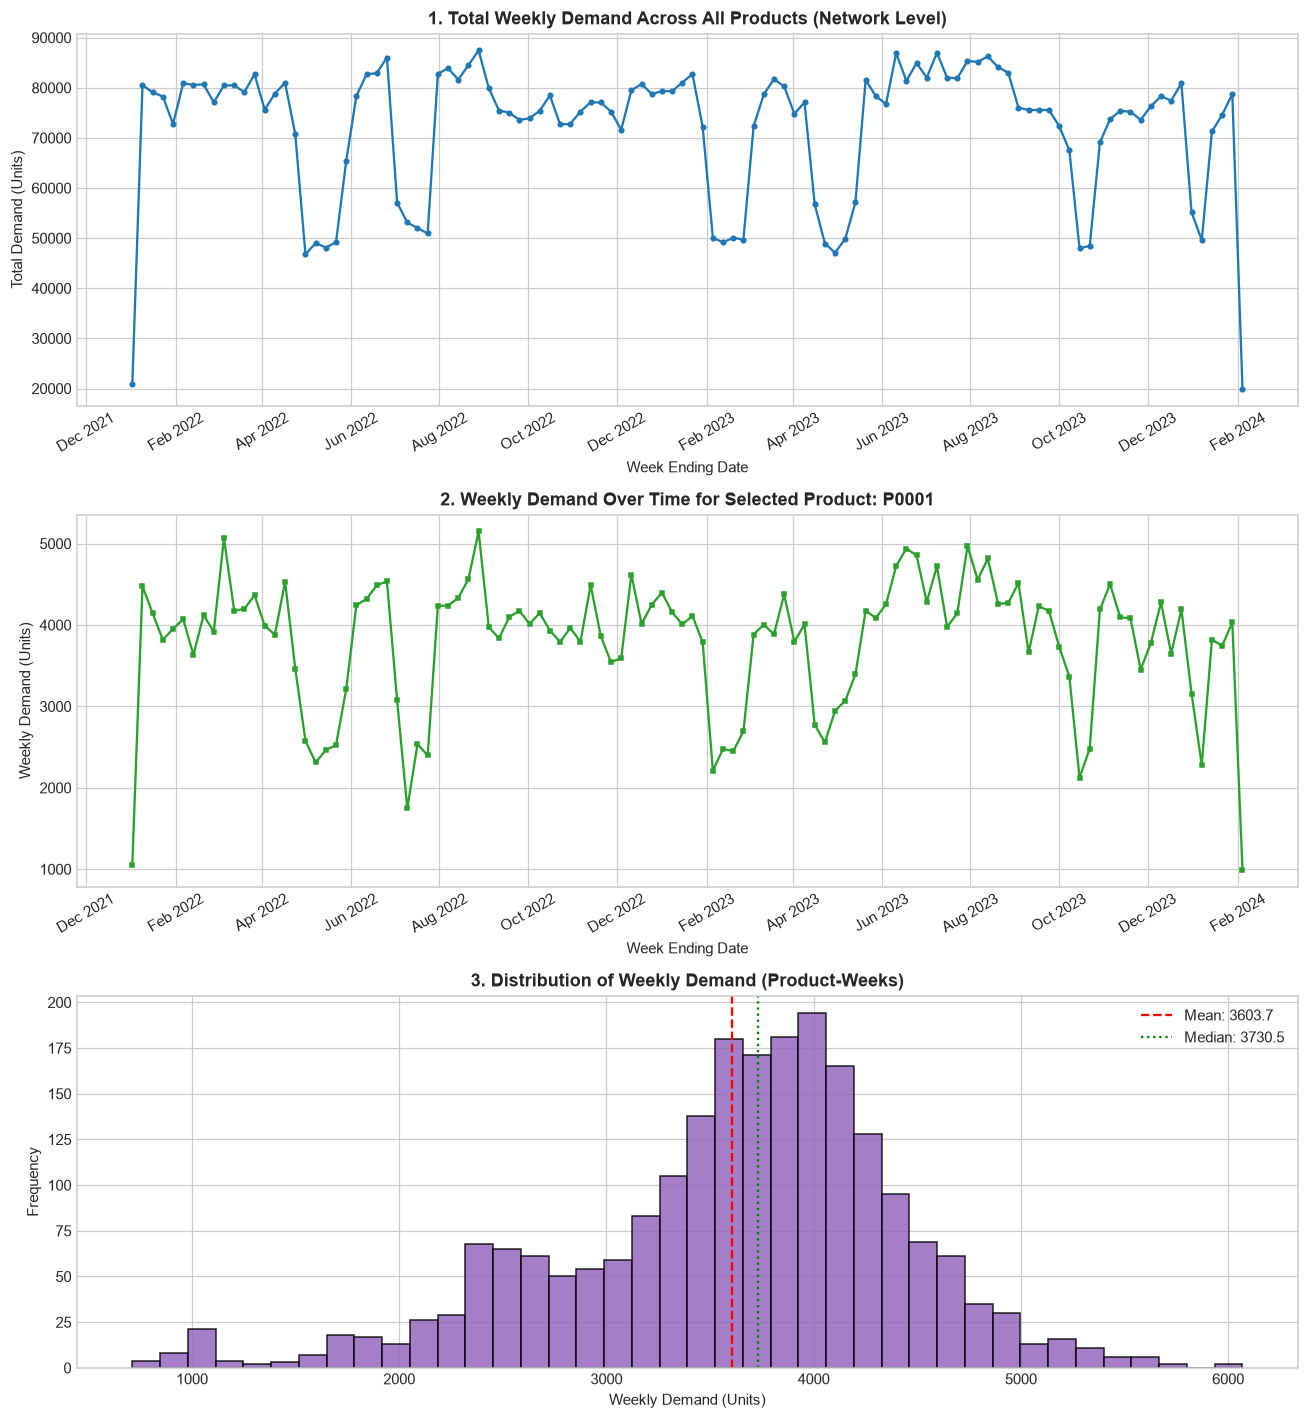

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 13))

# Plot 1: Total weekly demand across all products
total_weekly = weekly_df.groupby('Week_Ending')['Weekly_Demand'].sum().reset_index()
axes[0].plot(total_weekly['Week_Ending'], total_weekly['Weekly_Demand'], color='#1f77b4', marker='o', markersize=3)
axes[0].set_title('1. Total Weekly Demand Across All Products (Network Level)', fontweight='bold')
axes[0].set_xlabel('Week Ending Date')
axes[0].set_ylabel('Total Demand (Units)')
axes[0].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
axes[0].tick_params(axis='x', rotation=30)

# Plot 2: Selected Product P0001 weekly demand
selected_product = sorted(weekly_df['Product ID'].unique())[0]  # P0001
p_data = weekly_df[weekly_df['Product ID'] == selected_product]
axes[1].plot(p_data['Week_Ending'], p_data['Weekly_Demand'], color='#2ca02c', marker='s', markersize=3)
axes[1].set_title(f'2. Weekly Demand Over Time for Selected Product: {selected_product}', fontweight='bold')
axes[1].set_xlabel('Week Ending Date')
axes[1].set_ylabel('Weekly Demand (Units)')
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
axes[1].tick_params(axis='x', rotation=30)

# Plot 3: Histogram of product-week demand
axes[2].hist(weekly_df['Weekly_Demand'], bins=40, color='#9467bd', edgecolor='black', alpha=0.85)
axes[2].axvline(weekly_df['Weekly_Demand'].mean(), color='red', linestyle='--', label=f'Mean: {weekly_df["Weekly_Demand"].mean():.1f}')
axes[2].axvline(weekly_df['Weekly_Demand'].median(), color='green', linestyle=':', label=f'Median: {weekly_df["Weekly_Demand"].median():.1f}')
axes[2].set_title('3. Distribution of Weekly Demand (Product-Weeks)', fontweight='bold')
axes[2].set_xlabel('Weekly Demand (Units)')
axes[2].set_ylabel('Frequency')
axes[2].legend()

plt.tight_layout()
plt.show()

### 7. Four-Week Trailing Moving Average Baseline
Compute the 4-week trailing moving average per product, using `shift(1)` to strictly prevent current-week target leakage.

In [7]:
# Apply trailing 4-week moving average with shift(1) per Product ID
weekly_df['Moving_Average_4W'] = (
    weekly_df.sort_values(by=['Product ID', 'Week_Ending'])
    .groupby('Product ID')['Weekly_Demand']
    .transform(lambda s: s.shift(1).rolling(window=4, min_periods=4).mean())
)

display(weekly_df[weekly_df['Product ID'] == selected_product][['Product ID', 'Week_Ending', 'Weekly_Demand', 'Moving_Average_4W']].head(8))

,Product ID,Week_Ending,Weekly_Demand,Moving_Average_4W
0,P0001,2022-01-02,1057,NaN
1,P0001,2022-01-09,4476,NaN
2,P0001,2022-01-16,4143,NaN
3,P0001,2022-01-23,3818,NaN
4,P0001,2022-01-30,3952,3373.50
5,P0001,2022-02-06,4071,4097.25
6,P0001,2022-02-13,3632,3996.00
7,P0001,2022-02-20,4121,3868.25


### 8. Chronological Train / Test Split & Rolling Evaluation Set
Split weeks chronologically (80% train / 20% test) on unique calendar weeks and create the rolling one-week-ahead evaluation dataset.

In [8]:
# Chronological split on unique week-ending dates
unique_weeks_series = pd.Series(sorted(weekly_df['Week_Ending'].unique()))
train_count = int(np.floor(0.80 * len(unique_weeks_series)))
test_count = len(unique_weeks_series) - train_count

train_weeks = unique_weeks_series.iloc[:train_count]
test_weeks = unique_weeks_series.iloc[train_count:]
split_date = test_weeks.iloc[0]

train_df = weekly_df[weekly_df['Week_Ending'].isin(train_weeks)].copy()
test_df = weekly_df[weekly_df['Week_Ending'].isin(test_weeks)].copy()

# Create evaluation dataframe
eval_df = test_df[['Product ID', 'Week_Ending', 'Weekly_Demand', 'Moving_Average_4W']].rename(
    columns={'Weekly_Demand': 'Actual_Demand', 'Moving_Average_4W': 'Predicted_Demand'}
).copy().reset_index(drop=True)

print(f"Training Period: {train_weeks.iloc[0].strftime('%Y-%m-%d')} to {train_weeks.iloc[-1].strftime('%Y-%m-%d')} ({train_count} weeks, {len(train_df):,} rows)")
print(f"Testing Period:  {test_weeks.iloc[0].strftime('%Y-%m-%d')} to {test_weeks.iloc[-1].strftime('%Y-%m-%d')} ({test_count} weeks, {len(test_df):,} rows)")
print(f"Split Date:      {split_date.strftime('%Y-%m-%d')}")
print(f"Valid Test Predictions: {eval_df['Predicted_Demand'].notna().sum():,} (Exclusions: {eval_df['Predicted_Demand'].isna().sum()})")
display(eval_df.head(10))

Training Period: 2022-01-02 to 2023-09-03 (88 weeks, 1,760 rows)
Testing Period:  2023-09-10 to 2024-02-04 (22 weeks, 440 rows)
Split Date:      2023-09-10
Valid Test Predictions: 440 (Exclusions: 0)


,Product ID,Week_Ending,Actual_Demand,Predicted_Demand
0,P0001,2023-09-10,3664,4465.75
1,P0001,2023-09-17,4231,4177.50
2,P0001,2023-09-24,4172,4170.25
3,P0001,2023-10-01,3734,4145.75
4,P0001,2023-10-08,3367,3950.25
5,P0001,2023-10-15,2125,3876.00
6,P0001,2023-10-22,2480,3349.50
7,P0001,2023-10-29,4191,2926.50
8,P0001,2023-11-05,4500,3040.75
9,P0001,2023-11-12,4093,3324.00


### 9. Baseline Evaluation Metrics
Calculate MAE (primary), RMSE, and R² on all valid test prediction rows.

In [9]:
y_true = eval_df['Actual_Demand']
y_pred = eval_df['Predicted_Demand']

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
r2 = r2_score(y_true, y_pred)

metrics_df = pd.DataFrame({
    'Metric': ['Mean Absolute Error (MAE)', 'Root Mean Squared Error (RMSE)', 'R-squared (R²)'],
    'Value': [mae, rmse, r2],
    'Role': ['Primary Evaluation Metric', 'Supporting Metric', 'Supporting Metric']
})

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")
display(metrics_df)

MAE:  663.6295
RMSE: 880.2499
R²:   -0.1101


,Metric,Value,Role
0,Mean Absolute Error (MAE),663.629545,Primary Evaluation Metric
1,Root Mean Squared Error (RMSE),880.249896,Supporting Metric
2,R-squared (R²),-0.110128,Supporting Metric


### 10. Test-Period Forecast Visualizations
Plot actual vs. predicted values for Product `P0001` over the 22-week test window, and scatter plot of actual vs. predicted demand across all test observations.

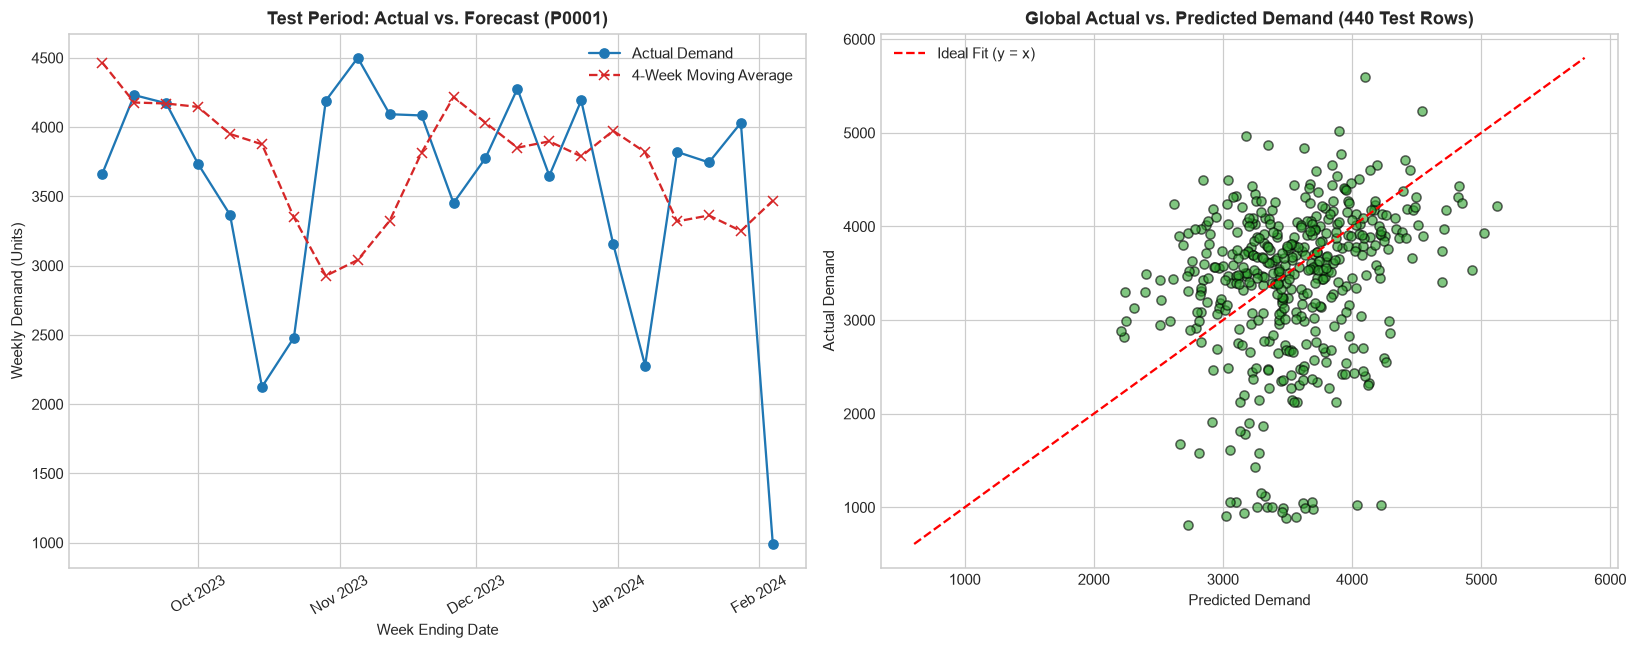

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Test trajectory for Product P0001
p_eval = eval_df[eval_df['Product ID'] == selected_product].sort_values('Week_Ending')
axes[0].plot(p_eval['Week_Ending'], p_eval['Actual_Demand'], color='#1f77b4', marker='o', label='Actual Demand')
axes[0].plot(p_eval['Week_Ending'], p_eval['Predicted_Demand'], color='#d62728', marker='x', linestyle='--', label='4-Week Moving Average')
axes[0].set_title(f'Test Period: Actual vs. Forecast ({selected_product})', fontweight='bold')
axes[0].set_xlabel('Week Ending Date')
axes[0].set_ylabel('Weekly Demand (Units)')
axes[0].xaxis.set_major_locator(mdates.MonthLocator(interval=1))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
axes[0].tick_params(axis='x', rotation=30)
axes[0].legend()

# Scatter plot: Actual vs Predicted
axes[1].scatter(eval_df['Predicted_Demand'], eval_df['Actual_Demand'], color='#2ca02c', alpha=0.6, edgecolors='k')
min_val = min(eval_df['Predicted_Demand'].min(), eval_df['Actual_Demand'].min()) - 200
max_val = max(eval_df['Predicted_Demand'].max(), eval_df['Actual_Demand'].max()) + 200
axes[1].plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Ideal Fit (y = x)')
axes[1].set_title('Global Actual vs. Predicted Demand (440 Test Rows)', fontweight='bold')
axes[1].set_xlabel('Predicted Demand')
axes[1].set_ylabel('Actual Demand')
axes[1].legend()

plt.tight_layout()
plt.show()

### 11. Verified Results Summary & Next Steps
- **Evaluated Test Rows**: 440 product-weeks (20 products x 22 weeks)
- **Primary Metric (MAE)**: **663.63 units**
- **Supporting RMSE**: **880.25 units**
- **Supporting R²**: **-0.1101**
- **Next Step**: Compare Random Forest Regressor in Notebook 02 against this baseline using the identical chronological test set and target.